## Agent publisher

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mzarnecki/course_llm_agent_apps_with_langchain_and_langgraph/blob/main/notebooks/en/9_1_Application_agent_publisher_en.ipynb)

| | |
|---|---|
| 🎯 **What you'll learn** | Build a multi-agent publisher: researcher, author and critic agents that write and revise an article. |
| 🔑 **API keys** | `OPENAI_API_KEY`, `TAVILY_API_KEY` |
| 💲 **API cost** | moderate – multi-agent loop with many longer requests |
| ⏱️ **Run time** | ~2–5 min |

### Install libraries

In [ ]:
# Install this notebook's direct dependencies.
# Skipped when pip is missing, e.g. in the `uv sync` environment, which already has them (see README).
import importlib.util
if importlib.util.find_spec("pip"):
    %pip install -qU langgraph langgraph-supervisor langchain-tavily langchain-openai python-dotenv
# Google Colab: add OPENAI_API_KEY in the Secrets panel (🔑) and grant this notebook access.
# Uncomment these lines to load it from Colab Secrets into this runtime:
# from google.colab import userdata
# import os
# os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
# Locally, put OPENAI_API_KEY=... in a .env file; do not commit the key.
# For Tavily search, also add TAVILY_API_KEY to Colab Secrets or your local .env file.
# from google.colab import userdata
# os.environ["TAVILY_API_KEY"] = userdata.get("TAVILY_API_KEY")

In [2]:
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
from langchain_tavily import TavilySearch

web_search = TavilySearch(max_results=3)
web_search_results = web_search.invoke("Who is the prime minister of Poland?")

print(web_search_results["results"][0]["content"])

Donald Franciszek Tusk (born 22 April 1957) is a Polish politician and historian who has served as the prime minister of Poland since 2023, previously holding the office from 2007 to 2014. Tusk was President of the European Council from 2014 to 2019 and led the European People's Party from 2019 to 2022. He co-founded the Civic Platform (PO), one of the dominant Polish political parties, and was its longtime leader – from 2003 to 2014 and again from 2021 to 2025 – before it merged into the Civic [...] | Tusk in 2025 |
| Prime Minister of Poland |
| Incumbent |
| Assumed office  13 December 2023 |
| President | Andrzej Duda Karol Nawrocki |
| Deputy | Władysław Kosiniak-Kamysz   Krzysztof Gawkowski   Radosław Sikorski |
| Preceded by | Mateusz Morawiecki |
| In office 16 November 2007 – 22 September 2014 |
| President | Lech Kaczyński Acting (2010)    Bronisław Komorowski  Bogdan Borusewicz  Grzegorz Schetyna Bronisław Komorowski | [...] Prime Minister of Poland (2007–2014; since 2023)



### Pretty printing helper functions

In [4]:
from langchain_core.messages import convert_to_messages


def pretty_print_messages(update):
    """Print the newest message from each node update produced by graph.stream()."""
    for node_name, node_update in update.items():
        print(f"Update from node {node_name}:\n")
        convert_to_messages(node_update["messages"])[-1].pretty_print()
        print("\n")

### Agent researcher

In [5]:
from langchain_core.output_parsers import StrOutputParser
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate

model = ChatOpenAI(model="gpt-6.1-sol")

def research_agent_node(state):
    messages = state["messages"]
    user_request = messages[0].content  # BaseMessage OK

    search_results = web_search.invoke(user_request)
    research_content = []
    for result in search_results["results"][:3]:
        research_content.append(f"Source: {result['url']}\nContent: {result['content']}\n")
    research_text = "\n---\n".join(research_content)

    research_prompt = ChatPromptTemplate.from_messages([
("system", """You're the Researcher. You have access to fragments from the 'search engine' (RESEARCH).
Your goal is to provide factual, concise facts and data supporting the topic.
Refer to the fragments and do not invent. Write concretely and briefly.
After you finish your task, respond directly to the moderator.
Reply using only the results of your work, do not include the text."""),
("user", "Topic: {topic}\n\nSearch results:\n{research_data}")

    ])

    chain = research_prompt | model | StrOutputParser()
    response = chain.invoke({"topic": user_request, "research_data": research_text})

    return {"messages": [{"role": "assistant", "content": response, "name": "research_agent"}]}


### Agent author

In [6]:
from langchain_core.messages import BaseMessage

def _name_and_content(msg):
    if isinstance(msg, dict):
        return msg.get("name", msg.get("role", "user")), msg.get("content", str(msg))
    if isinstance(msg, BaseMessage):
        name = getattr(msg, "name", None) or getattr(msg, "type", "user")
        return name, msg.content
    # fallback
    return "user", str(msg)


In [7]:
def author_agent_node(state):
    messages = state["messages"]
    has_critic_already_intervened = state.get("critic_marked", False)

    if has_critic_already_intervened:
        author_prompt = ChatPromptTemplate.from_messages([
("system", """You're the Expert-Editor. You have already received feedback from the Critic and you must improve your text.
Analyze the critic's comments and provide a revised version of the article that addresses their concerns.
Include all suggestions and fill in the indicated gaps. Write concretely.
After you finish your task, respond directly to the moderator.
Reply using only the results of your work, do not include the text."""),
("user", "Conversation history:\n{conversation_history}\n\nRevise the article taking into account the critic's feedback.")

        ])
    else:
        author_prompt = ChatPromptTemplate.from_messages([
("system", """You're the Expert. From the available facts, propose a practical solution/plan.
Include steps, requirements, and a minimal set of decisions. Write concretely.
After you finish your task, respond directly to the moderator.
Reply using only the results of your work, do not include the text."""),
("user", "Based on the research, create an article:\n{conversation_history}")

        ])

    conversation_history = "\n".join(
        f"{_name_and_content(m)[0]}: {_name_and_content(m)[1]}"
        for m in messages
    )

    chain = author_prompt | model | StrOutputParser()
    response = chain.invoke({"conversation_history": conversation_history})

    return {"messages": [{"role": "assistant", "content": response, "name": "author_agent"}]}


### Agent critic

In [8]:
def critic_agent_node(state):
    messages = state["messages"]

    conversation_history = "\n".join(
        f"{_name_and_content(m)[0]}: {_name_and_content(m)[1]}"
        for m in messages
    )

    critic_prompt = ChatPromptTemplate.from_messages([
("system", """You're the Critic. Your role is to find gaps, risks, and ambiguities in the proposal.
Ask probing questions and point out missing elements. Be constructive.
After analyzing the author's work, if you see significant gaps or problems, end your response with the words: "needs improvement"
If the work is satisfactory and does not require significant corrections, end with the words: "approved"
After you finish your task, respond directly to the moderator.
Reply using only the results of your work, do not include the text."""),
("user", "Analyze the author's work:\n{conversation_history}")
    ])

    chain = critic_prompt | model | StrOutputParser()
    response = chain.invoke({"conversation_history": conversation_history})

    updates = {
        "messages": [{"role": "assistant", "content": response, "name": "critic_agent"}]
    }
    if not state.get("critic_marked", False):
        updates["critic_marked"] = True

    return updates


def should_continue(state):
    last = state["messages"][-1]
    _, content = _name_and_content(last)
    content = content.lower()
    return "author_agent" if "needs improvement" in content else "end"

### Build graph

In [9]:
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

class WorkflowState(TypedDict):
    messages: Annotated[list, add_messages]
    critic_marked: bool

supervisor = (
    StateGraph(WorkflowState)
    .add_node("research_agent", research_agent_node)
    .add_node("author_agent", author_agent_node)
    .add_node("critic_agent", critic_agent_node)
    .add_edge(START, "research_agent")
    .add_edge("research_agent", "author_agent")
    .add_edge("author_agent", "critic_agent")
    .add_conditional_edges("critic_agent", should_continue, {
        "author_agent": "author_agent",
        "end": END
    })
    .compile()
)


### Display graph

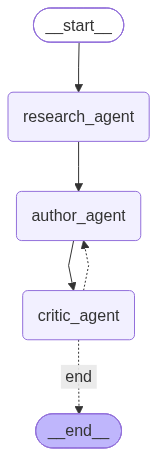

In [10]:
from IPython.display import display, Image

display(Image(supervisor.get_graph().draw_mermaid_png()))

### Run graph and generate the article

In [11]:
for chunk in supervisor.stream(
    {
        "messages": [{
            "role": "user",
            "content": "Generate an article on the topic: How to build a 'Publisher' agent application based on the LangGraph library",
        }],
        "critic_marked": False,
    },
):
    pretty_print_messages(chunk)


Update from node research_agent:

================================== Ai Message ==================================
Name: research_agent

## Building a “Publisher” agent with LangGraph

### Core architecture

LangGraph orchestrates stateful, multi-step workflows as graphs. Nodes perform work, while shared state carries information between steps. It supports cyclic execution, making it suitable for drafting, reviewing, and revising content. Nodes read the current state and return partial updates; reducers determine how updates merge, particularly for message histories. [2]

LangGraph can run without LangChain chains or LCEL. LangChain integrations are useful for models, prompts, and tools, but are not mandatory. [3]

### Suggested Publisher workflow

A practical design is:

**Brief → Research → Draft → Review → Revise if needed → Approve → Publish**

This is a proposed application architecture, not a predefined LangGraph workflow.

1. **Define the publishing brief.** Capture the topic, a

Update from node author_agent:

================================== Ai Message ==================================
Name: author_agent

# How to Build a “Publisher” Agent Application with LangGraph

A Publisher agent turns an editorial brief into content that is researched, drafted, reviewed, approved, and delivered to a publishing destination.

The challenge is not generating the first draft. It is controlling what happens next: checking the article, limiting revisions, preserving progress, and ensuring that publication happens only after approval.

LangGraph fits this problem because it represents a workflow as a graph of operations sharing state. It also supports cycles, allowing an article to move through review and revision more than once. [2]

This article builds a practical starting point:

**Brief → Research preparation → Draft → Review → Revise → Human approval → Publish**

This is an application design, not a predefined LangGraph agent.

## 1. Make Four Decisions First

Keep the

Update from node critic_agent:

================================== Ai Message ==================================
Name: critic_agent

Moderator, the article is well structured and makes important distinctions between automated review, human approval, revision limits, and execution limits. Its prototype boundaries and CMS retry guidance are particularly useful. However, the runnable example needs a correction before approval.

### Blocking issue: graph node conflicts with a state field

`PublisherState` defines a `draft` field, while the graph also registers a node named `"draft"`. LangGraph rejects node names that collide with state keys, so graph construction fails before the example can run.

Rename the node while retaining the state field:

```python
builder.add_node("draft_article", draft)
```

Update the registration dictionary and both affected edges accordingly:

```python
builder.add_edge("research", "draft_article")
builder.add_edge("draft_article", "review")
```

Run the compl

Update from node author_agent:

================================== Ai Message ==================================
Name: author_agent

# How to Build a “Publisher” Agent Application with LangGraph

A Publisher agent turns an editorial brief into a researched, reviewed, approved, and published article. Generating the first draft is only one step. A useful application must also control revisions, preserve progress, and prevent publication without authorization.

LangGraph provides the orchestration primitives for this workflow: shared state, processing nodes, conditional routing, checkpoints, and human-in-the-loop interrupts.

This tutorial builds:

**Brief → Prepare sources → Draft → Review → Revise if needed → Human approval → Publish**

The example publishes a local Markdown file—not a public website. It also includes a deterministic smoke test that exercises the workflow without calling a model.

## 1. Architecture and Editorial Policy

Start with explicit boundaries:

| Concern | Prot

Update from node critic_agent:

================================== Ai Message ==================================
Name: critic_agent

Moderator, the revision addresses the earlier blocking issue and is satisfactory as a clearly scoped prototype tutorial.

- **Graph construction:** The drafting node is now named `draft_article`, avoiding the collision with the `draft` state field.
- **Testability:** Dependency injection and the deterministic smoke test cover revision, approval interruption, resumption, and publication without API credentials.
- **Technical grounding:** Official documentation now supports the graph, persistence, interrupt, and streaming explanations.
- **Scope and limitations:** The article clearly distinguishes terminal escalation from interruption, in-memory from durable persistence, and source preparation from independent research.
- **Publication safeguards:** Authorization, draft-bound approval, replay-safe side effects, and CMS idempotency receive appropriate attent